---
title: 3.10 Riesgos compuestos y cascadas
short_title: 3.10 Riesgos compuestos y cascadas
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/sincelejo/blob/main/book/03_analisis/310_multiamenaza.ipynb)

**Reproducible sin red en el checkout.** La fuente preservada y sus limitaciones se describen en el capítulo 2.3.


In [1]:
from pathlib import Path
import sys, subprocess, json
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'src/sincelejo/analisis.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/sincelejo')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/mromerot/sincelejo.git',str(ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(ROOT)+'[libro]'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sincelejo.analisis import cargar, indicadores, deficit_trimestral, sensibilidad_calor
clima = cargar(ROOT/'data/raw/power_1991_2025.json')
anual = indicadores(clima)
evidencia = pd.read_json(ROOT/'data/evidencia.json')
plt.rcParams.update({'figure.figsize':(9,4), 'axes.spines.top':False, 'axes.spines.right':False})


## Dependencias a comprobar

Las cadenas siguientes son hipótesis causales de planificación. No se han estimado sus probabilidades conjuntas.

In [2]:
cadenas=pd.DataFrame([['Sequía y calor','Mayor demanda de agua/energía','Interrupción de servicio','Agua y respaldo de energía'],['Tormenta','Daño de redes eléctricas','Falla de bombeo y distribución','Redundancia y recuperación'],['Lluvia intensa','Obstrucción de drenaje o falla de talud','Corte de acceso y respuesta tardía','Rutas y mantenimiento'],['Intermitencia de agua','Almacenamiento doméstico','Condiciones favorables para vectores','Continuidad y manejo sanitario'],['Sismo','Daño de tanques/redes','Afectación prolongada de servicios','Evaluación y refuerzo']],columns=['iniciador','mecanismo','consecuencia_posible','medida_transversal'])
display(cadenas)

,iniciador,mecanismo,consecuencia_posible,medida_transversal
0,Sequía y calor,Mayor demanda de agua/energía,Interrupción de servicio,Agua y respaldo de energía
1,Tormenta,Daño de redes eléctricas,Falla de bombeo y distribución,Redundancia y recuperación
2,Lluvia intensa,Obstrucción de drenaje o falla de talud,Corte de acceso y respuesta tardía,Rutas y mantenimiento
3,Intermitencia de agua,Almacenamiento doméstico,Condiciones favorables para vectores,Continuidad y manejo sanitario
4,Sismo,Daño de tanques/redes,Afectación prolongada de servicios,Evaluación y refuerzo


## Coincidencia meteorológica observada en el producto

El conteo seco–cálido usa la referencia mensual fija. No prueba causalidad de incendios o desabastecimiento.

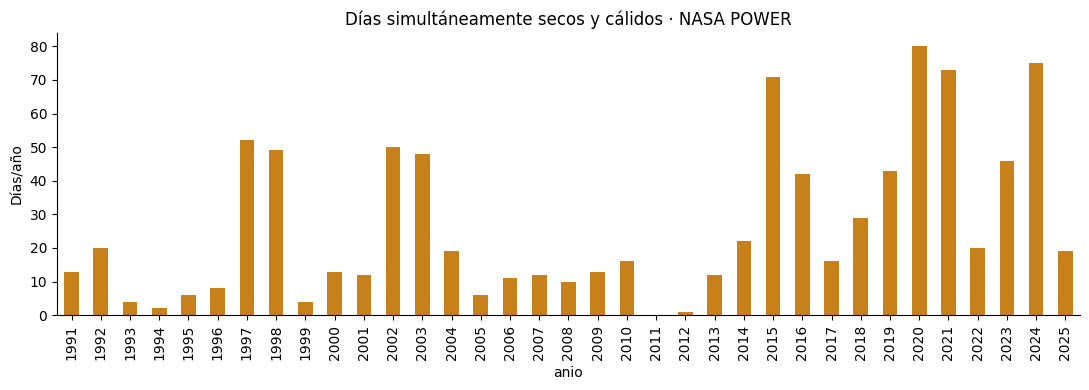

In [3]:
anual.compuesto.plot.bar(color='#c8811a',figsize=(11,4),title='Días simultáneamente secos y cálidos · NASA POWER'); plt.ylabel('Días/año'); plt.tight_layout(); plt.show()

## Evitar doble conteo

Una vivienda dañada por lluvia y deslizamiento durante el mismo episodio no puede sumarse dos veces como pérdida total. La expectativa de la suma de pérdidas bien definidas es la suma de expectativas, incluso si existe dependencia; la dependencia importa para la distribución conjunta y las pérdidas extremas. Las interacciones pueden cambiar las propias pérdidas, por ejemplo al impedir atención o reparación.

La representación correcta usa identificadores de activos y episodios, reglas de atribución y tiempos de recuperación. No se suman índices normalizados de sequía, calor y sismo para obtener COP ni una probabilidad de desastre.

## Robustez de medidas

La continuidad de agua, energía y acceso conecta varias amenazas. Una medida debe probarse con fallas simultáneas y con sectores vulnerables; una mejora promedio puede esconder un grupo que pierde servicio. Evaluar también redundancias que comparten la misma fuente de falla.